# Notebook 12 — LSTM no PulseDB (Etapa 6, Fase 1)

**Mudança de abordagem.** Até aqui os modelos usaram as 43 features (uma linha de números por ciclo). A LSTM usa a **forma de onda do PPG** (o segmento inteiro, amostra por amostra) e aprende os padrões temporais sozinha. É o que o Prof. Renan tinha interesse em ver.

**Fase 1 (este notebook):** montar e validar a LSTM **dentro do PulseDB** (treino + validação com separação por sujeito).
**Fase 2 (depois):** testar a LSTM treinada no PTT-PPG, com calibração por sujeito — fechando a comparação direta **RandomForest (features) × LSTM (forma de onda)**.

**Como rodar:** a primeira execução vem em modo `USAR_SMOKE_TEST = True` (arquivo AAMI, 666 segmentos) só para confirmar que o pipeline roda em segundos. Os números desse modo NÃO importam (poucos dados). Depois, troque para `False` para treinar de verdade no CalBased.

## 1. Importações e configuração

In [1]:
import os
import gc
import socket
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mat73
from scipy.signal import butter, filtfilt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks

warnings.filterwarnings("ignore")
np.random.seed(42)
tf.random.set_seed(42)

plt.rcParams["figure.facecolor"]  = "white"
plt.rcParams["axes.facecolor"]    = "white"
plt.rcParams["savefig.facecolor"] = "white"
plt.rcParams["savefig.dpi"] = 300

print("Computador:", socket.gethostname())
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("Inicio:", datetime.now().strftime("%d/%m/%Y %H:%M:%S"))

Computador: NtebookLeticia
TensorFlow: 2.21.0 | Keras: 3.15.0
Inicio: 25/06/2026 14:46:17


## 2. Caminhos e parâmetros

In [2]:
BASE_IC      = Path(r"C:\IC_PPG")
PASTA_PULSEDB = (BASE_IC / "data" / "pulsedb_kaggle" / "datasets" /
                 "weinanwangrutgers" / "pulsedb-balanced-training-and-testing" /
                 "versions" / "4")
PASTA_MODELO = BASE_IC / "saved_models" / "ptt_ppg"
PASTA_DADOS  = BASE_IC / "data" / "ptt_ppg"
PASTA_FIGS   = BASE_IC / "figures"

# Sinal e pre-processamento
FS_ORIGINAL   = 125          # Hz (PulseDB)
FREQ_INF, FREQ_SUP, ORDEM = 0.5, 8.0, 4   # filtro Butterworth (igual ao NB07)
FATOR_DOWNSAMPLE = 5         # 125 Hz -> 25 Hz (PPG vai ate ~8 Hz, sobra folga)

# Treino
MAX_SEGMENTOS = None         # None = usar todos; ou um numero para limitar (memoria/tempo)
TEST_SIZE_SUJEITOS = 0.2     # fracao de SUJEITOS para validacao
EPOCAS = 50
BATCH  = 64
print("Parametros comuns definidos.")

Parametros comuns definidos.


### Escolha do modo — rode APENAS UMA das duas células abaixo

A célula que você rodar por **último** é a que vale. Para o teste rápido, rode só a **Opção A**. Para o treino real, rode só a **Opção B** (não precisa rodar a A antes). Depois é só seguir o notebook normalmente.

In [3]:
# ═════════ OPÇÃO A — SMOKE TEST (AAMI, 666 segmentos, segundos) ═════════
# Rode SO esta celula para o teste rapido de pipeline. Os numeros NAO importam.
USAR_SMOKE_TEST = True
ARQ_MAT = PASTA_PULSEDB / "VitalDB_AAMI_Test_Subset.mat"
if not ARQ_MAT.exists():
    raise FileNotFoundError(ARQ_MAT)
print("MODO: SMOKE TEST  |  arquivo:", ARQ_MAT.name)

MODO: SMOKE TEST  |  arquivo: VitalDB_AAMI_Test_Subset.mat


In [ ]:
# ═════════ OPÇÃO B — TREINO REAL (CalBased, 1,46 GB) ═════════
# Rode SO esta celula para treinar de verdade (mesmo conjunto da inversao RF).
USAR_SMOKE_TEST = False
ARQ_MAT = PASTA_PULSEDB / "VitalDB_CalBased_Test_Subset.mat"
if not ARQ_MAT.exists():
    raise FileNotFoundError(ARQ_MAT)
print("MODO: TREINO REAL (CalBased)  |  arquivo:", ARQ_MAT.name)

## 3. Carregar o `.mat` e extrair a forma de onda do PPG

Mesma estrutura do NB07: `Subset` com `Signals` (canal 1 = PPG), `SBP`, `DBP`, `Subject`. Aqui pegamos o **segmento inteiro** do PPG (não fatiamos em ciclos) e logo liberamos a estrutura grande da memória.

In [4]:
print("Carregando", ARQ_MAT.name, "...")
inicio = datetime.now()
dados  = mat73.loadmat(str(ARQ_MAT))
subset = dados["Subset"]

signals = np.asarray(subset["Signals"])          # (n_seg, canais, amostras)
print("Shape de Signals:", signals.shape)
ppg_raw = signals[:, 1, :].astype(np.float32)    # canal 1 = PPG -> (n_seg, amostras)

sbp = np.asarray(subset["SBP"], dtype=np.float32).ravel()
dbp = np.asarray(subset["DBP"], dtype=np.float32).ravel()

# subject pode vir como string, lista ou array -> normaliza para string
def _subj(x):
    if isinstance(x, (list, np.ndarray)) and len(x) > 0:
        return f"v{x[0]}"
    return f"v{x}"
sujeitos = np.array([_subj(s) for s in subset["Subject"]])

# libera a estrutura grande
del dados, subset, signals
gc.collect()

print(f"Carregado em {(datetime.now()-inicio).total_seconds():.1f} s")
print(f"Segmentos: {ppg_raw.shape[0]} | amostras/segmento: {ppg_raw.shape[1]} | "
      f"sujeitos: {len(np.unique(sujeitos))}")
print(f"PAS [{sbp.min():.0f}-{sbp.max():.0f}] | PAD [{dbp.min():.0f}-{dbp.max():.0f}] mmHg")

Carregando VitalDB_AAMI_Test_Subset.mat ...
Shape de Signals: (666, 3, 1250)
Carregado em 0.6 s
Segmentos: 666 | amostras/segmento: 1250 | sujeitos: 116
PAS [73-214] | PAD [38-132] mmHg


## 4. Pré-processamento da forma de onda

Para cada segmento: filtro passa-banda 0,5–8 Hz (igual ao NB07), reamostragem para 25 Hz (a LSTM em CPU fica muito mais rápida) e normalização z-score por segmento (a rede vê a *forma*, não a amplitude absoluta do PPG, que é arbitrária).

In [5]:
b_coef, a_coef = butter(ORDEM, [FREQ_INF/(FS_ORIGINAL/2), FREQ_SUP/(FS_ORIGINAL/2)],
                        btype="band")

def preparar_segmento(sinal):
    """Filtra, reamostra e normaliza um segmento de PPG."""
    filt = filtfilt(b_coef, a_coef, sinal)          # passa-banda, fase preservada
    filt = filt[::FATOR_DOWNSAMPLE]                  # 125 Hz -> 25 Hz
    mu, sd = filt.mean(), filt.std()
    return (filt - mu) / sd if sd > 1e-8 else filt - mu   # z-score por segmento

# Opcional: limitar quantidade de segmentos (memoria/tempo)
n_total = ppg_raw.shape[0]
if MAX_SEGMENTOS is not None and n_total > MAX_SEGMENTOS:
    idx_amostra = np.random.RandomState(42).choice(n_total, MAX_SEGMENTOS, replace=False)
    ppg_raw, sbp, dbp, sujeitos = ppg_raw[idx_amostra], sbp[idx_amostra], dbp[idx_amostra], sujeitos[idx_amostra]
    print(f"Limitado a {MAX_SEGMENTOS} segmentos.")

# Aplica o pre-processamento a todos os segmentos
X = np.stack([preparar_segmento(s) for s in ppg_raw]).astype(np.float32)
X = X[..., np.newaxis]                               # (n, T, 1) -> formato da LSTM
y = np.column_stack([sbp, dbp]).astype(np.float32)  # (n, 2) -> [PAS, PAD]
T = X.shape[1]

del ppg_raw; gc.collect()
print(f"X: {X.shape} (n, passos_de_tempo, 1) | y: {y.shape} [PAS, PAD] | T = {T} passos")

X: (666, 250, 1) (n, passos_de_tempo, 1) | y: (666, 2) [PAS, PAD] | T = 250 passos


### Conferência visual de um segmento

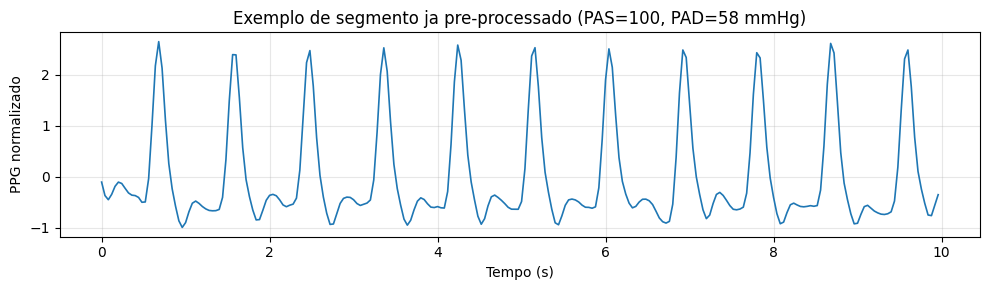

In [6]:
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(np.arange(T) / (FS_ORIGINAL/FATOR_DOWNSAMPLE), X[0, :, 0], lw=1.2)
ax.set_xlabel("Tempo (s)"); ax.set_ylabel("PPG normalizado")
ax.set_title(f"Exemplo de segmento ja pre-processado (PAS={y[0,0]:.0f}, PAD={y[0,1]:.0f} mmHg)")
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 5. Separação treino/validação por sujeito (sem vazamento)

In [7]:
gss = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE_SUJEITOS, random_state=42)
idx_treino, idx_val = next(gss.split(X, y, groups=sujeitos))

X_tr, X_val = X[idx_treino], X[idx_val]
y_tr, y_val = y[idx_treino], y[idx_val]

print(f"Treino: {X_tr.shape[0]} segmentos | {len(np.unique(sujeitos[idx_treino]))} sujeitos")
print(f"Valid.: {X_val.shape[0]} segmentos | {len(np.unique(sujeitos[idx_val]))} sujeitos")
# Conferindo que nenhum sujeito aparece nos dois conjuntos
assert set(sujeitos[idx_treino]).isdisjoint(set(sujeitos[idx_val])), "Vazamento de sujeito!"
print("Sem sobreposicao de sujeitos (OK).")

Treino: 519 segmentos | 92 sujeitos
Valid.: 147 segmentos | 24 sujeitos
Sem sobreposicao de sujeitos (OK).


## 6. Padronização dos alvos

Padroniza PAS/PAD (média e desvio do treino) para estabilizar o treinamento; as métricas são calculadas depois em mmHg, revertendo a escala.

In [8]:
y_mean = y_tr.mean(axis=0)
y_std  = y_tr.std(axis=0)
y_tr_s  = (y_tr  - y_mean) / y_std
y_val_s = (y_val - y_mean) / y_std
print("Media (PAS, PAD):", np.round(y_mean, 1), "| Desvio:", np.round(y_std, 1))

Media (PAS, PAD): [132.9  73.6] | Desvio: [31.5 18.2]


## 7. Construir a LSTM (Keras)

Duas camadas LSTM (64 e 32 unidades) que leem a forma de onda, com dropout para regularizar, seguidas de uma camada densa e da saída com 2 valores (PAS e PAD).

In [9]:
def construir_lstm(n_passos):
    modelo = keras.Sequential([
        keras.Input(shape=(n_passos, 1)),
        layers.LSTM(64, return_sequences=True),   # le a sequencia inteira
        layers.Dropout(0.2),
        layers.LSTM(32),                           # resume em um vetor
        layers.Dropout(0.2),
        layers.Dense(32, activation="relu"),
        layers.Dense(2),                           # saida: [PAS, PAD] (padronizados)
    ])
    modelo.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=["mae"])
    return modelo

modelo = construir_lstm(T)
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 250, 64)        │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 250, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,434 (118.88 KB)

 Trainable params: 30,434 (118.88 KB)

 Non-trainable params: 0 (0.00 B)

## 8. Treinar

`EarlyStopping` interrompe quando a validação para de melhorar e restaura os melhores pesos. Em CPU, cada época pode levar de segundos (smoke test) a alguns minutos (CalBased).

In [10]:
parada = callbacks.EarlyStopping(monitor="val_loss", patience=8,
                                 restore_best_weights=True, verbose=1)

print("Treinando...")
inicio = datetime.now()
hist = modelo.fit(
    X_tr, y_tr_s,
    validation_data=(X_val, y_val_s),
    epochs=EPOCAS, batch_size=BATCH,
    callbacks=[parada], verbose=2,
)
print(f"Treino concluido em {(datetime.now()-inicio).total_seconds()/60:.1f} min")

Treinando...
Epoch 1/50
9/9 - 4s - 489ms/step - loss: 1.0019 - mae: 0.8374 - val_loss: 0.9353 - val_mae: 0.7863
Epoch 2/50
9/9 - 1s - 141ms/step - loss: 0.9996 - mae: 0.8365 - val_loss: 0.9348 - val_mae: 0.7858
Epoch 3/50
9/9 - 1s - 134ms/step - loss: 0.9967 - mae: 0.8352 - val_loss: 0.9384 - val_mae: 0.7876
Epoch 4/50
9/9 - 1s - 129ms/step - loss: 0.9942 - mae: 0.8341 - val_loss: 0.9453 - val_mae: 0.7914
Epoch 5/50
9/9 - 1s - 131ms/step - loss: 0.9921 - mae: 0.8333 - val_loss: 0.9506 - val_mae: 0.7940
Epoch 6/50
9/9 - 1s - 141ms/step - loss: 0.9919 - mae: 0.8333 - val_loss: 0.9405 - val_mae: 0.7902
Epoch 7/50
9/9 - 1s - 128ms/step - loss: 0.9818 - mae: 0.8290 - val_loss: 0.9413 - val_mae: 0.7917
Epoch 8/50
9/9 - 1s - 143ms/step - loss: 0.9596 - mae: 0.8181 - val_loss: 0.9923 - val_mae: 0.8212
Epoch 9/50
9/9 - 1s - 128ms/step - loss: 0.9121 - mae: 0.7950 - val_loss: 1.0245 - val_mae: 0.8543
Epoch 10/50
9/9 - 1s - 129ms/step - loss: 0.8413 - mae: 0.7594 - val_loss: 1.0204 - val_mae: 0.8

## 9. Avaliação na validação (MAE / R² / BHS / AAMI)

In [11]:
def metricas_completas(y_real, y_pred):
    y_real = np.asarray(y_real); y_pred = np.asarray(y_pred)
    erros = y_real - y_pred; abs_e = np.abs(erros)
    return {
        "MAE": mean_absolute_error(y_real, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_pred)),
        "R2": r2_score(y_real, y_pred),
        "ME": float(np.mean(erros)), "SD": float(np.std(erros, ddof=1)),
        "pct_5": 100*float(np.mean(abs_e <= 5)),
        "pct_10": 100*float(np.mean(abs_e <= 10)),
        "pct_15": 100*float(np.mean(abs_e <= 15)),
        "n": int(len(y_real)),
    }
def classificar_bhs(p5, p10, p15):
    if p5>=60 and p10>=85 and p15>=95: return "A"
    if p5>=50 and p10>=75 and p15>=90: return "B"
    if p5>=40 and p10>=65 and p15>=85: return "C"
    return "D"
def classificar_aami(me, sd): return "PASSA" if (abs(me)<=5 and sd<=8) else "FALHA"

# Predicao na validacao -> reverte a padronizacao para mmHg
y_pred_s = modelo.predict(X_val, verbose=0)
y_pred   = y_pred_s * y_std + y_mean

linhas = []
for j, alvo in [(0, "PAS"), (1, "PAD")]:
    m = metricas_completas(y_val[:, j], y_pred[:, j])
    m["BHS"]  = classificar_bhs(m["pct_5"], m["pct_10"], m["pct_15"])
    m["AAMI"] = classificar_aami(m["ME"], m["SD"])
    m["alvo"] = alvo
    linhas.append(m)
df_lstm = pd.DataFrame(linhas)[["alvo","n","MAE","RMSE","R2","ME","SD","pct_5","pct_10","pct_15","BHS","AAMI"]]

print("LSTM — validacao dentro do PulseDB" + ("  [SMOKE TEST — ignorar numeros]" if USAR_SMOKE_TEST else ""))
print("="*100)
print(df_lstm.round(2).to_string(index=False))

LSTM — validacao dentro do PulseDB  [SMOKE TEST — ignorar numeros]
alvo   n   MAE  RMSE    R2   ME    SD  pct_5  pct_10  pct_15 BHS  AAMI
 PAS 147 22.91 28.52 -0.07 7.40 27.64  14.29   28.57   40.14   D FALHA
 PAD 147 15.38 18.66 -0.25 8.26 16.79  23.13   34.69   48.98   D FALHA


## 10. Figuras — curva de treino e dispersão (PAS)

Figura salva em: C:\IC_PPG\figures\nb12_lstm_pulsedb.png


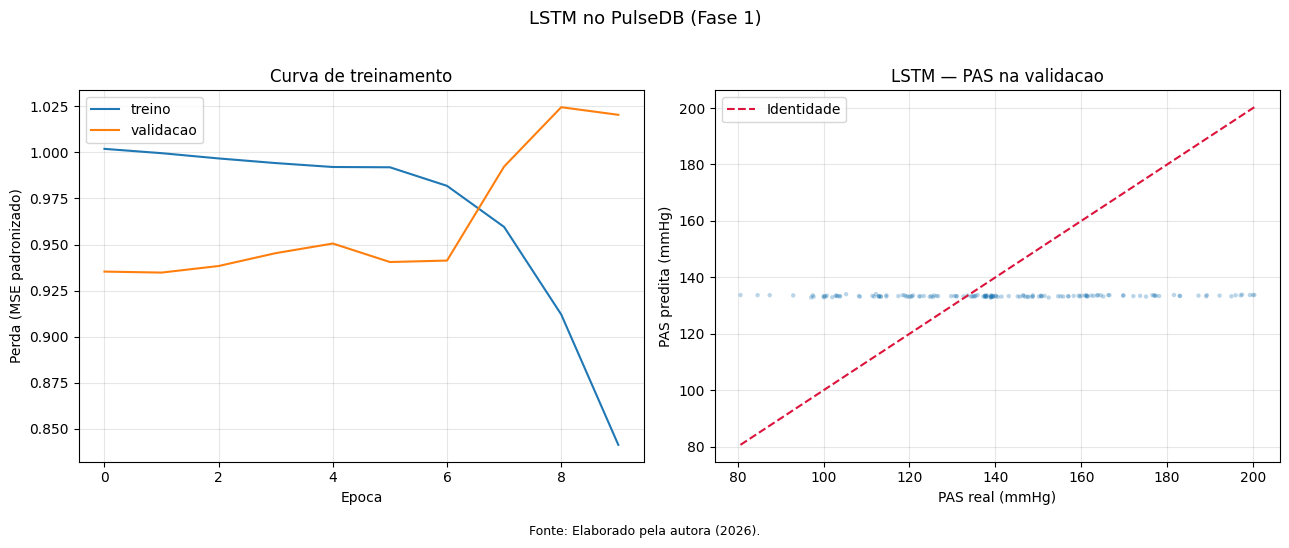

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Curva de perda
axes[0].plot(hist.history["loss"], label="treino")
axes[0].plot(hist.history["val_loss"], label="validacao")
axes[0].set_xlabel("Epoca"); axes[0].set_ylabel("Perda (MSE padronizado)")
axes[0].set_title("Curva de treinamento"); axes[0].legend(); axes[0].grid(alpha=0.3)

# Dispersao PAS
axes[1].scatter(y_val[:, 0], y_pred[:, 0], s=10, alpha=0.3, edgecolors="none")
lo, hi = float(y_val[:,0].min()), float(y_val[:,0].max())
axes[1].plot([lo, hi], [lo, hi], "--", color="crimson", lw=1.5, label="Identidade")
axes[1].set_xlabel("PAS real (mmHg)"); axes[1].set_ylabel("PAS predita (mmHg)")
axes[1].set_title("LSTM — PAS na validacao"); axes[1].legend(); axes[1].grid(alpha=0.3)

fig.suptitle("LSTM no PulseDB (Fase 1)", y=1.02, fontsize=13)
fig.text(0.5, -0.03, "Fonte: Elaborado pela autora (2026).", ha="center", fontsize=9)
fig.tight_layout()
PASTA_FIGS.mkdir(parents=True, exist_ok=True)
caminho_fig = PASTA_FIGS / "nb12_lstm_pulsedb.png"
fig.savefig(caminho_fig, dpi=300, bbox_inches="tight")
print("Figura salva em:", caminho_fig); plt.show()

## 11. Salvar modelo, histórico e métricas

In [13]:
sufixo = "smoke" if USAR_SMOKE_TEST else "calbased"
PASTA_MODELO.mkdir(parents=True, exist_ok=True)
modelo.save(PASTA_MODELO / f"lstm_pulsedb_{sufixo}.keras")
# guarda tambem a escala dos alvos (necessaria para usar o modelo depois, na Fase 2)
np.savez(PASTA_MODELO / f"lstm_pulsedb_{sufixo}_scaler.npz", y_mean=y_mean, y_std=y_std,
         T=T, fator_downsample=FATOR_DOWNSAMPLE)
pd.DataFrame(hist.history).to_csv(PASTA_DADOS / f"lstm_history_{sufixo}.csv", index=False)
df_lstm.to_csv(PASTA_DADOS / f"nb12_lstm_metrics_{sufixo}.csv", index=False)
print("Salvos: modelo .keras, escala .npz, histórico e métricas (sufixo:", sufixo, ")")

Salvos: modelo .keras, escala .npz, histórico e métricas (sufixo: smoke )


## 12. Conclusões e próximos passos

- Se este foi o **smoke test**, ignore os números — o objetivo era confirmar que o pipeline roda. Agora troque `USAR_SMOKE_TEST = False` e rode de novo para treinar no CalBased.
- **Fase 2:** carregar esta LSTM treinada e testá-la no PTT-PPG (aplicando a mesma calibração por sujeito da inversão), fechando a comparação RandomForest × LSTM.
- Comparar com a RF: a RF na inversão atingiu, com calibração de inclinação, MAE ~3 mmHg (estrato run). A pergunta do artigo é se a LSTM, sem features feitas à mão, chega perto.

In [14]:
print(f"Notebook 12 (LSTM, Fase 1) concluido em: {datetime.now().strftime('%d/%m/%Y %H:%M:%S')}")

Notebook 12 (LSTM, Fase 1) concluido em: 25/06/2026 14:48:20
